# 3.5 · Growth at a reasonable price (GARP)

**GARP** combines growth and value investing: buy companies with growing earnings and sales, but only those that are
also profitable, moderately leveraged and not expensive relative to their earnings. S&P Dow Jones Indices built it
into the **S&P 500 GARP Index** and published the rules in *Indexing GARP Strategies: A Practitioner's Guide* (July
2019). This notebook reconstructs the index from those rules on our own data and backtests it.

**The rules** (from the paper; rebalance timing from S&P's GARP index methodology):

| Step | Rule |
|---|---|
| Universe | the S&P 500's constituents on each reference date - the last business day of May and November |
| Growth | three-year compound annual growth of earnings per share and of sales per share |
| Quality & value | return on equity, financial leverage (total debt / book equity, lower is better), earnings yield (E/P) |
| Scores | each ratio winsorized at its 2.5th / 97.5th percentiles and standardised into a z-score; the growth and quality & value scores are averages of their z-scores, capped at +/-4 (equal weights; a parameter in the first code cell) |
| Filter 1 | the 150 highest growth scores |
| Filter 2 | of those, the 75 highest quality & value scores - the top 60 always, current constituents within the top 90 retained (a buffer) |
| Weights | proportional to growth score (1 + z, or 1 / (1 - z) for negative z), capped at 5 % per stock and 40 % per sector |
| Trading | after the close on the third Friday of June and December |

**Differences from the paper:**

* **Sample period.** The paper's backtest covers 1995-2019 (Compustat). Our statements start in 2005 and growth needs
  three years of them, so this test runs from June 2009 to the end of 2024; our hold-out (2025 on) stays untouched.
* **Data.** Statements as first reported (SEC, with LSEG before it), each figure used from its publication date; the
  paper instead lags Compustat's (restated) figures by 45 days. Per-share figures use each company's own share counts.
* **Costs.** The index bears no transaction costs; this portfolio pays 0.10 % per trade, like all our large-cap
  backtests.
* **Sectors** are today's GICS sectors for every date (our sector history begins when we first recorded it); the
  40 % cap rarely binds, so this matters little.
* **Benchmark.** SPY, the S&P 500 ETF, with dividends reinvested; the paper compares with the S&P 500 total return.
* One interpretation: a return on equity that is positive only because a loss is divided by negative equity, and
  leverage over negative equity, get the **worst** score of the day. The paper's wording, "the z-score of the 2.5
  percentile ranked security", only makes sense as a penalty.

In [1]:
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research.backtest import performance
from equity_research.research.cache import ResearchCache
from equity_research.research.classification import listing_sectors
from equity_research.research.garp import GarpConfig, run_garp
from equity_research.research.indices import calendar_years

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# The weights inside each composite - equal, the published rule. Only the ratios matter; any change is our
# variant and a new registered trial (earnings to price and one quality z-score stay required whatever their
# weights).
GROWTH_WEIGHTS = {"eps_growth": 1.0, "sales_growth": 1.0}
QUALITY_VALUE_WEIGHTS = {"leverage": 1.0, "roe": 1.0, "earnings_yield": 1.0}
config = GarpConfig(  # every other setting is the published rule
    start="2009-01-01",
    end="2024-12-31",
    growth_weights=GROWTH_WEIGHTS,
    quality_value_weights=QUALITY_VALUE_WEIGHTS,
)
result = run_garp(cache, config, engine=engine)
net = result.backtest.net
spy = result.benchmark.reindex(net.index)
print("Registered as research run", result.run_id, "- trials of this family so far:", result.metrics["trials"])
print(f"{len(result.book)} rebalances, {result.book.index.min():%d %b %Y} to {result.book.index.max():%d %b %Y}")

Registered as research run 110 - trials of this family so far: 1
32 rebalances, 19 Jun 2009 to 20 Dec 2024


## Performance

The reconstruction against SPY over the same dates, and, for scale, the paper's reported figures for 1995-2019. The
sample periods differ, so the paper's numbers are a reference point, not a target.

In [2]:
ours = pd.DataFrame({"GARP (our rebuild)": performance(net), "SPY": performance(spy)}).T
display(ours.style.format({"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}))
m = result.metrics
ACTIVE = {
    "beta": "{:.2f}",
    "alpha": "{:+.1%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
display(pd.DataFrame({"GARP against SPY": {k: m[k] for k in ACTIVE}}).T.style.format(ACTIVE))
paper = pd.DataFrame(
    {
        "S&P 500 GARP Index": {"return a year": 0.1328, "volatility": 0.1779, "return / risk": 0.75, "IR": 0.47},
        "S&P 500": {"return a year": 0.0981, "volatility": 0.1475, "return / risk": 0.67, "IR": float("nan")},
    }
).T
print("The paper, June 1995 - May 2019 (Exhibits 5 and 6):")
display(
    paper.style.format(
        {"return a year": "{:.1%}", "volatility": "{:.1%}", "return / risk": "{:.2f}", "IR": "{:.2f}"}, na_rep="-"
    )
)

,cagr,vol,sharpe,max_drawdown
GARP (our rebuild),12.5%,19.1%,0.71,-40%
SPY,14.8%,17.1%,0.89,-34%


,beta,alpha,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
GARP against SPY,1.11,-3.2%,-2.0%,5.9%,-0.27,14%,1.6


The paper, June 1995 - May 2019 (Exhibits 5 and 6):


,return a year,volatility,return / risk,IR
S&P 500 GARP Index,13.3%,17.8%,0.75,0.47
S&P 500,9.8%,14.8%,0.67,-


,GARP,SPY,ahead of SPY
trade_date,,,
2009,+24.5%,+22.3%,+2.2%
2010,+13.4%,+15.1%,-1.7%
2011,+4.2%,+1.9%,+2.3%
2012,+12.9%,+16.0%,-3.1%
2013,+37.9%,+32.3%,+5.6%
2014,+10.9%,+13.5%,-2.5%
2015,-6.7%,+1.3%,-7.9%
2016,+8.5%,+12.0%,-3.5%
2017,+23.8%,+21.7%,+2.1%


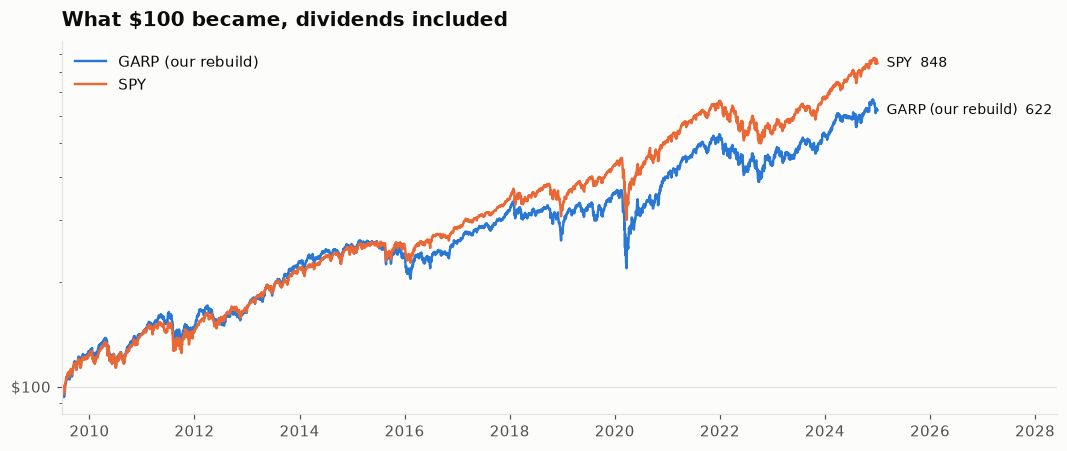

In [3]:
fig = charts.growth({"GARP (our rebuild)": net, "SPY": spy}, "What $100 became, dividends included")
years = calendar_years({"GARP": net, "SPY": spy})
years["ahead of SPY"] = years["GARP"] - years["SPY"]
display(years.style.format("{:+.1%}"))

## Portfolio characteristics

The number of holdings, their concentration and the portfolio's tilts - the paper's own diagnostics (Exhibits 7 and
8): the strategy should tilt towards growth, and its sector deviations from the S&P 500 should stay moderate.

Companies held: [75]; largest single weight ever: 2.9%
Turnover: 1.6 times a year


S&P 500 members with each score on each reference date (out of about 500):


,2009-05-29,2009-11-30,2010-05-28,2010-11-30,2011-05-31,2011-11-30,2012-05-31,2012-11-30,2013-05-31,2013-11-29,2014-05-30,2014-11-28,2015-05-29,2015-11-30,2016-05-31,...,2017-11-30,2018-05-31,2018-11-30,2019-05-31,2019-11-29,2020-05-29,2020-11-30,2021-05-28,2021-11-30,2022-05-31,2022-11-30,2023-05-31,2023-11-30,2024-05-31,2024-11-29
growth score,454,455,458,458,455,459,462,453,471,470,478,479,488,486,484,...,489,494,496,493,491,487,487,494,490,494,493,496,495,497,495
quality & value score,473,467,490,491,495,496,497,498,498,497,497,499,500,502,503,...,505,505,503,503,500,499,502,504,501,498,500,503,503,500,501


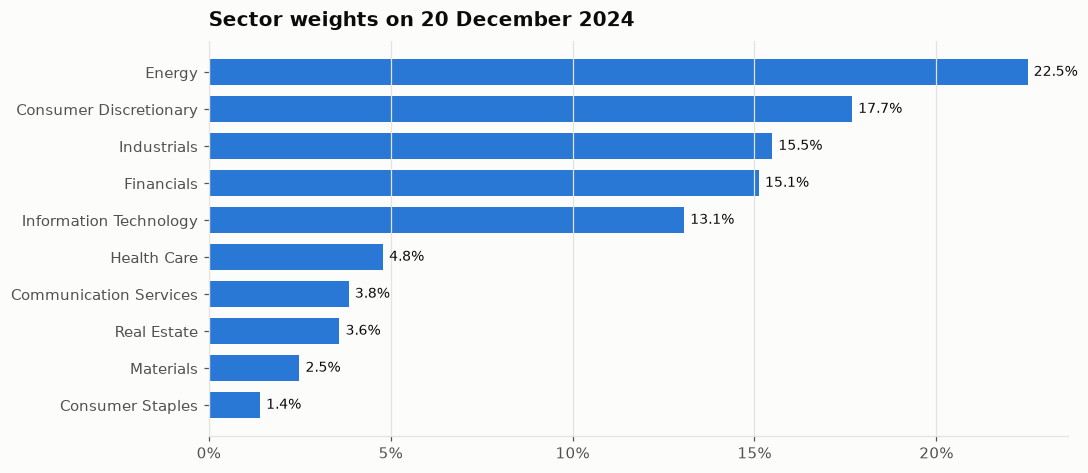

In [4]:
book = result.book
counts = sorted(set((book > 0).sum(axis=1).tolist()))
print(f"Companies held: {counts}; largest single weight ever: {book.max(axis=1).max():.1%}")
print(f"Turnover: {m['turnover']:.1f} times a year")
day = book.index[-1]
held = book.loc[day][book.loc[day] > 0]
sectors = listing_sectors(cache, held.index, day)
weights = held.groupby(sectors.reindex(held.index).to_numpy()).sum().sort_values(ascending=False)
fig = charts.ranked_bars(weights, f"Sector weights on {day:%d %B %Y}", percent=True)
refs = result.growth_z.index[result.growth_z.index.month.isin(config.reference_months)]
scored = pd.DataFrame(
    {
        "growth score": result.growth_z.loc[refs].notna().sum(axis=1),
        "quality & value score": result.quality_value_z.loc[refs].notna().sum(axis=1),
    }
)
print("S&P 500 members with each score on each reference date (out of about 500):")
display(scored.T)

## Fidelity of the reconstruction

The S&P 500 GARP Index has been calculated live since February 2019, and the Invesco S&P 500 GARP ETF (**SPGP**) has
tracked it since **24 June 2019** (before that the fund, then PXLG, tracked a Russell pure-growth index). From that
date the reconstruction can be compared with the real index. Two adjustments make the comparison like-for-like: the
reconstruction is taken **before** transaction costs (the index bears none), and SPGP's **0.36 %** annual expense
ratio is added back.

An exact reconstruction would show a daily return correlation near 1 and a tracking error near 0.

,cagr,vol,sharpe,max_drawdown
"rebuild, before costs",12.6%,23.4%,0.63,-40%
SPGP + its fee,13.9%,23.9%,0.66,-42%
SPGP as traded,13.4%,23.9%,0.65,-42%
SPY,15.1%,20.3%,0.79,-34%


Rebuild against the real index: daily correlation 0.982, beta 0.99, tracking error 4.5% a year, return gap -1.1% a year
The real index against SPY: -1.1% a year


,rebuild,real index,rebuild minus real
trade_date,,,
2019,+10.1%,+14.1%,-4.0%
2020,+12.4%,+16.1%,-3.7%
2021,+31.6%,+36.0%,-4.3%
2022,-17.2%,-13.5%,-3.7%
2023,+21.6%,+20.7%,+0.9%
2024,+17.4%,+8.9%,+8.5%


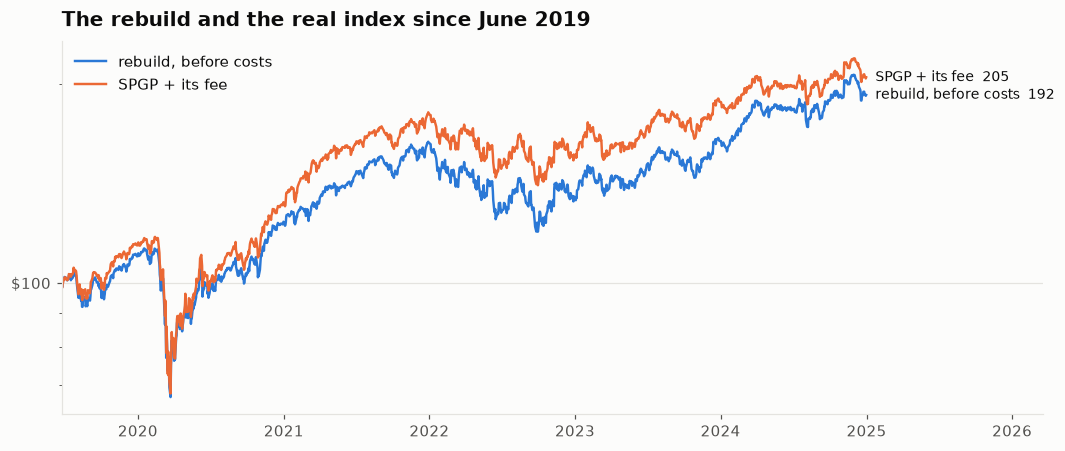

In [5]:
from equity_research.research.backtest import active_performance
from equity_research.research.indices import vendor_returns

since = pd.Timestamp("2019-06-24")
window = net.index[net.index >= since]
FEE = 0.0036 / 252  # SPGP's expense ratio, a trading day's share
spgp = vendor_returns(cache, "SPGP", total=True).reindex(window)
lines = {
    "rebuild, before costs": result.backtest.gross.reindex(window),
    "SPGP + its fee": spgp + FEE,
    "SPGP as traded": spgp,
    "SPY": result.benchmark.reindex(window),
}
display(
    pd.DataFrame({name: performance(r) for name, r in lines.items()}).T.style.format(
        {"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}
    )
)
closeness = active_performance(lines["rebuild, before costs"], lines["SPGP + its fee"])
both = pd.concat({"rebuild": lines["rebuild, before costs"], "index": lines["SPGP + its fee"]}, axis=1).dropna()
print(
    f"Rebuild against the real index: daily correlation {both.corr().iloc[0, 1]:.3f}, beta {closeness['beta']:.2f}, "
    f"tracking error {closeness['tracking_error']:.1%} a year, return gap {closeness['active_return']:+.1%} a year"
)
real_vs_spy = active_performance(lines["SPGP + its fee"], lines["SPY"])
print(f"The real index against SPY: {real_vs_spy['active_return']:+.1%} a year")
gaps = calendar_years({"rebuild": lines["rebuild, before costs"], "real index": lines["SPGP + its fee"]})
gaps["rebuild minus real"] = gaps["rebuild"] - gaps["real index"]
display(gaps.style.format("{:+.1%}"))
fig = charts.growth(
    {"rebuild, before costs": lines["rebuild, before costs"], "SPGP + its fee": lines["SPGP + its fee"]},
    "The rebuild and the real index since June 2019",
)

## Findings

* **The reconstruction trails SPY.** From June 2009 to the end of 2024 it returned 12.5 % a year against SPY's 14.8 %,
  with higher volatility (19.1 % against 17.1 %) and a deeper maximum drawdown (-40 % against -34 %): an active
  return of -2.0 % a year, an information ratio of -0.27, and a 14 % probability that the active bet reflects skill
  rather than luck (the first and only trial in this family).
* **It does not reproduce the paper's result - but the sample period differs.** The paper's information ratio of 0.47
  covers 1995-2019, including the 2000-2002 bear market, when cheap, profitable growth stocks held up far better than
  expensive ones. Our data starts in 2005, so those years cannot be tested; from 2009 the market was led by the
  largest growth companies.
* **Sources of the shortfall.** The portfolio holds 75 stocks weighted by growth score - none above 2.9 % - against a
  cap-weighted index, so it is heavily underweight the mega-caps that dominate SPY. It also tilts towards cyclical
  sectors (a beta of 1.11). Its worst years were the ones those tilts hurt: 2015 and 2018 (energy and cyclicals), 2020
  and 2024 (the mega-cap rally).
* **The reconstruction behaves as designed:** 75 holdings at every rebalance, scores for about 455-497 of the 500
  constituents each time (the rest lack three years of statements), and annual turnover of 1.6.

**Fidelity.** Against the real index (SPGP with its fee added back) since June 2019, the reconstruction moves with
it - a daily correlation of 0.98 and a beta of 0.99 - but not in lockstep: a tracking error of 4.5 % a year and 1.1 %
a year less return. The gap is not stable: about 4 points behind in each of 2019-2022, then 1 and 8.5 points ahead in
2023 and 2024. So the reconstruction captures the strategy's systematic exposures (sector tilts, beta, volatility) but
at times holds a noticeably different set of stocks. Plausible causes, not yet tested: the index uses Compustat data
(EPS before unusual items, restated figures) where ours is as first reported; its fundamentals are sampled some
weeks before each reference date; and its sectors are point-in-time, ours are today's.

**The strategy itself, not only the reconstruction, underperformed.** Over the same five and a half years the real
index trailed SPY by 1.1 % a year and the reconstruction (before costs) trailed the real index by another 1.1 %: about
half of the shortfall is GARP's own, in a period led by the largest growth stocks, and about half the
reconstruction's.

(Rerun on 31 October 2026 with the additional accounting items loaded; the results moved by 0.1 % a year or less.)

## Glossary

* **GARP** - growth at a reasonable price: growing companies that are neither expensive nor financially fragile.
* **z-score** - a value's distance from that date's cross-sectional mean, in standard deviations.
* **Winsorize** - replace values beyond the 2.5th and 97.5th percentiles with those percentiles, so outliers cannot
  dominate a mean or a standard deviation.
* **Buffer** - a rule that retains a current holding over a wider band than a new purchase needs, to reduce turnover
  around the cut-off.
* **Active return**, **information ratio**, **deflated Sharpe ratio** - see notebook 3.2.